<a href="https://colab.research.google.com/github/mrayhanz/244107020027-Machine-Learning/blob/main/Minggu%209/MRayhanZamzami_JS09_T2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# IDENTITAS DIRI

Nama : Muhammad Rayhan Zamzami

NIM : 244107020027

Kelas : TI-3G

Absen : 19

# TUGAS 2 - Komparasi Ekstraksi Fitur CountVectorizer vs TF-IDF pada Klasifikasi SMS Spam

Model: Multinomial Naive Bayes dengan stop_words='english'.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('dataset/spam.csv', encoding='latin-1')
df = df.drop(df.iloc[:, 2:], axis=1)
df.columns = ['Labels', 'SMS']
df['Labels'] = df['Labels'].map({'spam': 1, 'ham': 0})

X = np.array(df['SMS'])
y = np.array(df['Labels'])
df.head()

,Labels,SMS
0,0,"Go until jurong point, crazy.. Available only ..."
1,0,Ok lar... Joking wif u oni...
2,1,Free entry in 2 a wkly comp to win FA Cup fina...
3,0,U dun say so early hor... U c already then say...
4,0,"Nah I don't think he goes to usf, he lives aro..."


## 1. Pemodelan dengan CountVectorizer (stop_words='english')

In [2]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report

X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

cv = CountVectorizer(stop_words='english')
X_train_cv = cv.fit_transform(X_train_raw)
X_test_cv = cv.transform(X_test_raw)

model_cv = MultinomialNB()
model_cv.fit(X_train_cv, y_train)
y_pred_cv = model_cv.predict(X_test_cv)

print('=== Hasil CountVectorizer ===')
print(classification_report(y_test, y_pred_cv, target_names=['Ham', 'Spam']))

=== Hasil CountVectorizer ===
              precision    recall  f1-score   support

         Ham       0.99      0.99      0.99       966
        Spam       0.96      0.92      0.94       149

    accuracy                           0.98      1115
   macro avg       0.98      0.96      0.97      1115
weighted avg       0.98      0.98      0.98      1115



## 2. Pemodelan dengan TF-IDF (stop_words='english')

In [3]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(stop_words='english')
X_train_tfidf = tfidf.fit_transform(X_train_raw)
X_test_tfidf = tfidf.transform(X_test_raw)

model_tfidf = MultinomialNB()
model_tfidf.fit(X_train_tfidf, y_train)
y_pred_tfidf = model_tfidf.predict(X_test_tfidf)

print('=== Hasil TF-IDF ===')
print(classification_report(y_test, y_pred_tfidf, target_names=['Ham', 'Spam']))

=== Hasil TF-IDF ===
              precision    recall  f1-score   support

         Ham       0.97      1.00      0.98       966
        Spam       1.00      0.78      0.88       149

    accuracy                           0.97      1115
   macro avg       0.98      0.89      0.93      1115
weighted avg       0.97      0.97      0.97      1115



## 3. Tabel Perbandingan dan Visualisasi Metrik

,Ekstraksi Fitur,Jumlah Fitur,Akurasi,Presisi,Recall,F1-Score
0,CountVectorizer (Stop Words),7403,0.984753,0.964789,0.919463,0.941581
1,TF-IDF (Stop Words),7403,0.970404,1.000000,0.778523,0.875472


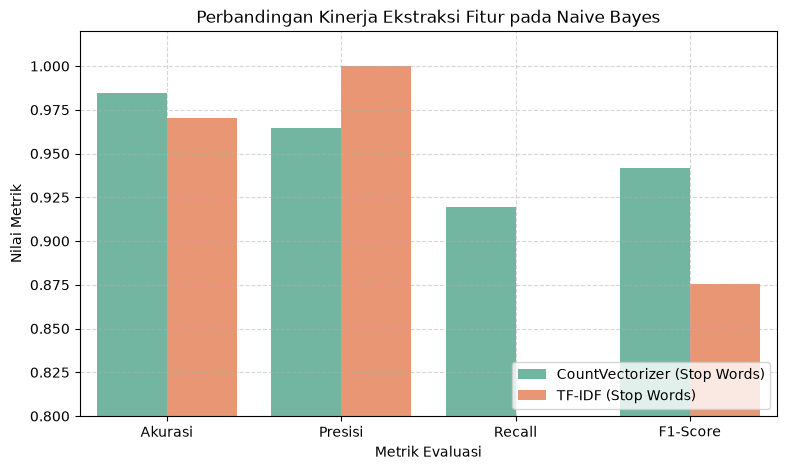

In [4]:
metrics_summary = pd.DataFrame([
    {
        'Ekstraksi Fitur': 'CountVectorizer (Stop Words)',
        'Jumlah Fitur': X_train_cv.shape[1],
        'Akurasi': accuracy_score(y_test, y_pred_cv),
        'Presisi': precision_score(y_test, y_pred_cv),
        'Recall': recall_score(y_test, y_pred_cv),
        'F1-Score': f1_score(y_test, y_pred_cv)
    },
    {
        'Ekstraksi Fitur': 'TF-IDF (Stop Words)',
        'Jumlah Fitur': X_train_tfidf.shape[1],
        'Akurasi': accuracy_score(y_test, y_pred_tfidf),
        'Presisi': precision_score(y_test, y_pred_tfidf),
        'Recall': recall_score(y_test, y_pred_tfidf),
        'F1-Score': f1_score(y_test, y_pred_tfidf)
    }
])

display(metrics_summary)

metrics_plot = metrics_summary.melt(id_vars='Ekstraksi Fitur', value_vars=['Akurasi', 'Presisi', 'Recall', 'F1-Score'])
plt.figure(figsize=(9, 5))
sns.barplot(data=metrics_plot, x='variable', y='value', hue='Ekstraksi Fitur', palette='Set2')
plt.ylim(0.8, 1.02)
plt.title('Perbandingan Kinerja Ekstraksi Fitur pada Naive Bayes')
plt.xlabel('Metrik Evaluasi')
plt.ylabel('Nilai Metrik')
plt.legend(loc='lower right')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()